Name:- UTKARSH MANI SINGH
ADM:-2026B15310067
COURSE:-AI/ML-6
BATCH DATA ANALYST 7

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
filename = 'Telco-Customer-Churn.csv'
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'

In [3]:

if not os.path.exists(filename):
    pd.read_csv(url).to_csv(filename, index=False)

df = pd.read_csv(filename)
df.head() #for first five rows

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info() #dataset structures and data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df.describe() #statistical details or summary

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
df.columns  #columns names

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [7]:
df.shape #no of rows or column

(7043, 21)

In [8]:
df.isnull().sum()  #this is used for missing values

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [9]:
# this is used for details of duplicate rows
df.duplicated().sum()

np.int64(0)

In [10]:
#  for categorical columns and their understandments
df.describe(include='object')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [11]:
df['Churn'].value_counts()
#for checking which columns are available named as churn

,count
Churn,
No,5174
Yes,1869


In [12]:
df['Churn'].value_counts(normalize=True)*100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [13]:
# to remove duplicate rows
df = df.drop_duplicates()

In [14]:
# to check missing values
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [15]:
# to remove extra speces we use strip and space is genrally called whitespace in coding language
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

In [16]:
# to convert columns into numbers
df['tenure'] = pd.to_numeric(df['tenure'], errors='coerce')
df['MonthlyCharges'] = pd.to_numeric(df['MonthlyCharges'], errors='coerce')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
#if a value cannot be converted into a number then
#pandas replaces it with NaN instead of producing an error thats why we use coerce

In [17]:
#to check missing values
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [18]:
#in this dataset missing totalcharges values may occur for customers whose tenure is zero.
df.loc[(df['tenure'] == 0) & (df['TotalCharges'].isnull()),'TotalCharges'] = 0

In [19]:
#to remove negative charges
df.loc[df['MonthlyCharges'] < 0, 'MonthlyCharges'] = np.nan
df.loc[df['TotalCharges'] < 0, 'TotalCharges'] = np.nan

#to remove rows without essential information
df = df.dropna(subset=['customerID', 'Churn'])

#to keep valid churn values
df = df[df['Churn'].isin(['Yes', 'No'])]

#to remove duplicate customers
df = df.drop_duplicates(subset='customerID')

In [20]:
#to convert Churn into numerical values
df['churn'] = (df['Churn'] == 'Yes').astype(int)

In [21]:
#to check cleaned dataset
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:")
print(df.isnull().sum())

df.head()

Rows: 7043
Columns: 22
Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
churn               0
dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [22]:
#group customers by tenure

tenure_groups = []

for tenure in df['tenure']:
    if tenure <= 12:
        tenure_groups.append('0-12 months')
    elif tenure <= 24:
        tenure_groups.append('13-24 months')
    elif tenure <= 48:
        tenure_groups.append('25-48 months')
    else:
        tenure_groups.append('49+ months')

df['tenure_group'] = tenure_groups


In [23]:
#group customers by monthly charges

billing_groups = []

for charge in df['MonthlyCharges']:
    if charge <= 40:
        billing_groups.append('Low')
    elif charge <= 80:
        billing_groups.append('Medium')
    else:
        billing_groups.append('High')

df['billing_group'] = billing_groups

In [24]:
#count services used by customers

services = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies']

df['service_count'] = (df[services] == 'Yes').sum(axis=1)

In [25]:
#check whether customer has tech support

df['support_plan'] = 'No'
df.loc[df['TechSupport'] == 'Yes', 'support_plan'] = 'Yes'

In [26]:
#display results

df[['tenure_group', 'billing_group', 'service_count', 'support_plan']].head()

,tenure_group,billing_group,service_count,support_plan
0,0-12 months,Low,1,No
1,25-48 months,Medium,2,No
2,0-12 months,Medium,2,No
3,25-48 months,Medium,3,Yes
4,0-12 months,Medium,0,No


In [27]:
#number of customers in each contract type
print("Customers by Contract:")
print(df.groupby('Contract')['churn'].count())

Customers by Contract:
Contract
Month-to-month    3875
One year          1473
Two year          1695
Name: churn, dtype: int64


In [28]:
#churn percentage by contract type
print("\nChurn Rate by Contract (%):")
print((df.groupby('Contract')['churn'].mean()*100).round(2))


Churn Rate by Contract (%):
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: churn, dtype: float64


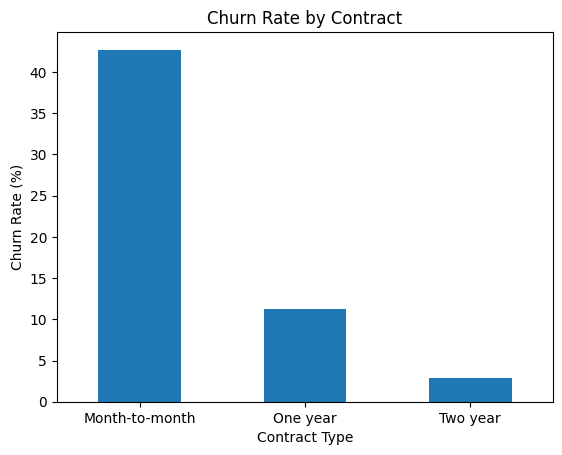

In [29]:
#Visualize churn by contract
churn_rate = df.groupby('Contract')['churn'].mean()*100

churn_rate.plot(kind='bar')

plt.title('Churn Rate by Contract')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [30]:
#number of customers by payment method
print("Customers by Payment Method:")
print(df.groupby('PaymentMethod')['churn'].count())

Customers by Payment Method:
PaymentMethod
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Electronic check             2365
Mailed check                 1612
Name: churn, dtype: int64


In [31]:
#churn percentage by payment method
print("\nChurn Rate by Payment Method (%):")
print((df.groupby('PaymentMethod')['churn'].mean()*100).round(2))


Churn Rate by Payment Method (%):
PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: churn, dtype: float64


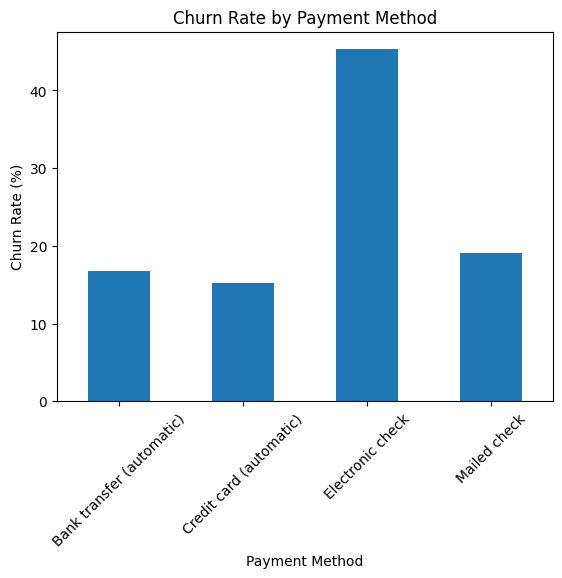

In [32]:
#barchart
#groupby() used group customers based on their payment method
#mean() used to calculates the average churn (0 = No, 1 = Yes)
#for percentage multiply it by 100
payment = df.groupby('PaymentMethod')['churn'].mean()*100

#plot() creates a graph from the data
#kind creates a bar chart as we used bar
payment.plot(kind='bar')

#to add title and labels to the graph
plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')

#xticks() controls the labels on the X-axis
plt.xticks(rotation=45)

#display the graph
plt.show()

In [33]:
#group customers by Internet Service and count them
print("Customers by Internet Service:")
print(df.groupby('InternetService')['churn'].count())

Customers by Internet Service:
InternetService
DSL            2421
Fiber optic    3096
No             1526
Name: churn, dtype: int64


In [34]:
#calculate churn percentage for each Internet Service
print("\nChurn Rate by Internet Service (%):")
print((df.groupby('InternetService')['churn'].mean()*100).round(2))


Churn Rate by Internet Service (%):
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: churn, dtype: float64


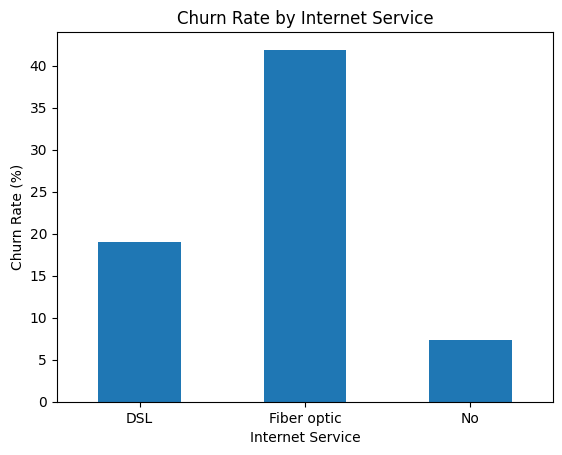

In [35]:
#groupby() groups customers by their Internet Service type
internet = df.groupby('InternetService')['churn'].mean()*100

#plot() creates a bar chart
internet.plot(kind='bar')

#add title and labels
plt.title('Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')

#rotate X-axis labels to make them readable
plt.xticks(rotation=0)

#display the chart
plt.show()

In [36]:
#columns used to group customers
groups = ['Contract', 'PaymentMethod', 'InternetService']

In [37]:
#count() counts customers in each combination
#groupby() creates groups based on all three columns
print("Number of Customers:")
print(df.groupby(groups)['churn'].count())

Number of Customers:
Contract        PaymentMethod              InternetService
Month-to-month  Bank transfer (automatic)  DSL                 197
                                           Fiber optic         327
                                           No                   65
                Credit card (automatic)    DSL                 185
                                           Fiber optic         293
                                           No                   65
                Electronic check           DSL                 474
                                           Fiber optic        1307
                                           No                   69
                Mailed check               DSL                 367
                                           Fiber optic         201
                                           No                  325
One year        Bank transfer (automatic)  DSL                 145
                                           Fiber 

In [38]:
#mean() calculates average churn for each combination
#multiplying by 100 converts it into percentage
print("\nChurn Rate by Combination (%):")
print((df.groupby(groups)['churn'].mean()*100).round(2))


Churn Rate by Combination (%):
Contract        PaymentMethod              InternetService
Month-to-month  Bank transfer (automatic)  DSL                19.80
                                           Fiber optic        45.57
                                           No                 20.00
                Credit card (automatic)    DSL                27.03
                                           Fiber optic        41.64
                                           No                  9.23
                Electronic check           DSL                40.51
                                           Fiber optic        60.37
                                           No                 18.84
                Mailed check               DSL                30.79
                                           Fiber optic        50.75
                                           No                 20.62
One year        Bank transfer (automatic)  DSL                 7.59
                         

In [39]:
#group customers using three columns
groups = ['Contract', 'PaymentMethod', 'InternetService']

In [40]:
#count customers in each combination
customers = df.groupby(groups)['churn'].count()

In [41]:
#calculate churn percentage for each combination
churnrate = df.groupby(groups)['churn'].mean()*100

In [42]:
#keep only combinations with at least 30 customers
churnrate = churnrate[customers>=30]

In [43]:
#sort churn rates from highest to lowest
churnrate = churn_rate.sort_values(ascending=False)

In [44]:
#display top 10 combinations
print("top 10 customer groups with highest Churn:")
print(churn_rate.head(10).round(2))

top 10 customer groups with highest Churn:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: churn, dtype: float64


In [45]:
#columns we want to compare
columns = ['tenure', 'MonthlyCharges', 'service_count']

for col in columns:

    #average for customers who left
    churnavg = df[df['churn'] == 1][col].mean()

    #average for customers who stayed
    stayedavg = df[df['churn'] == 0][col].mean()

    #difference between the two averages
    difference = churnavg - stayedavg

    print("\nFeature:", col)
    print("Churn Average:", round(churnavg, 2))
    print("Stayed Average:", round(stayedavg, 2))
    print("Difference:", round(difference, 2))


Feature: tenure
Churn Average: 17.98
Stayed Average: 37.57
Difference: -19.59

Feature: MonthlyCharges
Churn Average: 74.44
Stayed Average: 61.27
Difference: 13.18

Feature: service_count
Churn Average: 1.77
Stayed Average: 2.14
Difference: -0.37


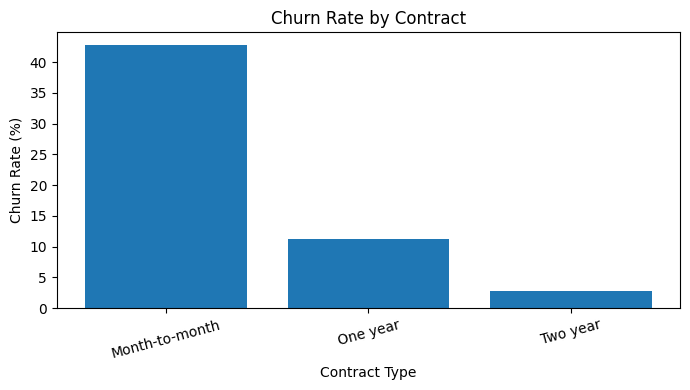

In [46]:
#group customers by contract type
#mean() calculates average churn
#multiplying by 100 converts it into percentage
contract = df.groupby('Contract')['churn'].mean()*100

#set the size of the graph
plt.figure(figsize=(7, 4))

#create a bar chart
plt.bar(contract.index, contract.values)

#add title and labels
plt.title('Churn Rate by Contract')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')

#rotate X-axis labels by 15 degrees
plt.xticks(rotation=15)

#adjust spacing so labels fit properly
plt.tight_layout()

#save the graph as a PNG image
plt.savefig('churn_by_contract.png')

#display the graph
plt.show()

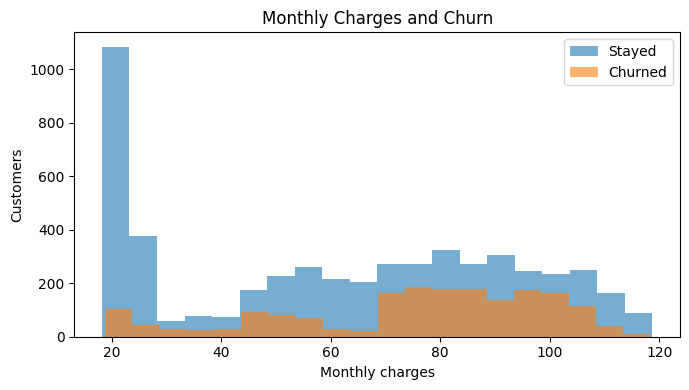

In [47]:
#set the size of the graph
plt.figure(figsize=(7, 4))

#to create histogram for customers who stayed
#dropna() helps to removes missing values
#bins=20 used to data is divided into 20 ranges
#alpha=0.6 used to make bar garph slightly transparent
plt.hist(df.loc[df['churn'] == 0, 'MonthlyCharges'].dropna(),
         bins=20, alpha=0.6, label='Stayed')

#to create histogram for customers who churned
#df['churn'] == 1 means customer left it just like flag variable used in wile
plt.hist(df.loc[df['churn'] == 1, 'MonthlyCharges'].dropna(),
         bins=20, alpha=0.6, label='Churned')

#label for X-axis
plt.xlabel('Monthly charges')

#label for Y-axis
plt.ylabel('Customers')

#title of the graph
plt.title('Monthly Charges and Churn')

#show labels for both histograms
plt.legend()

#adjust spacing so everything fits properly
plt.tight_layout()

#save the graph as an image file
plt.savefig('monthly_charges_comparison.png')

#display the graph
plt.show()

In [48]:
#create a table to check which columns are useful for churn prediction

leakagecheck = pd.DataFrame({
    'Column': ['customerID', 'Churn', 'TotalCharges',
               'Contract', 'tenure', 'PaymentMethod'],

    'Use': ['No', 'No', 'Caution', 'Yes', 'Yes', 'Yes'],

    'Reason': ['Customer ID only',
               'This is the result we want to predict',
               'Depends on how long customer has stayed',
               'Shows contract type',
               'Shows customer duration',
               'Shows payment method']
})

#to display the table
display(leakagecheck)

,Column,Use,Reason
0,customerID,No,Customer ID only
1,Churn,No,This is the result we want to predict
2,TotalCharges,Caution,Depends on how long customer has stayed
3,Contract,Yes,Shows contract type
4,tenure,Yes,Shows customer duration
5,PaymentMethod,Yes,Shows payment method


In [49]:
leakagecheck = pd.DataFrame({
    'column': ['customerID', 'Churn / churn', 'TotalCharges', 'Contract', 'tenure', 'PaymentMethod'],
    'use_in_risk_score': ['No', 'No', 'No', 'Yes', 'Yes', 'Yes'],
    'reason': ['ID only', 'Target (leakage)', 'Cumulative billing: use cautiously',
               'Known contract', 'Known tenure', 'Known payment type']})


In [50]:
display(leakagecheck)

,column,use_in_risk_score,reason
0,customerID,No,ID only
1,Churn / churn,No,Target (leakage)
2,TotalCharges,No,Cumulative billing: use cautiously
3,Contract,Yes,Known contract
4,tenure,Yes,Known tenure
5,PaymentMethod,Yes,Known payment type


In [51]:
#starting every customer with a risk score of 0
df['risk_score'] = 0

#adding 2 points for month-to-month contract
df.loc[df['Contract'] == 'Month-to-month', 'risk_score'] += 2

#adding 1 point if tenure is less than 12 months
df.loc[df['tenure'] < 12, 'risk_score'] += 1

#adding 1 point for electronic check payment
df.loc[df['PaymentMethod'] == 'Electronic check', 'risk_score'] += 1

#adding 1 point for fiber optic internet
df.loc[df['InternetService'] == 'Fiber optic', 'risk_score'] += 1


#divde customers into risk categories
df['risk_band'] = 'Low'

#scoring 2-3 means Medium risk
df.loc[(df['risk_score'] >= 2) & (df['risk_score'] <= 3), 'risk_band'] = 'Medium'

#scoring 4-5 means High risk
df.loc[df['risk_score'] >= 4, 'risk_band'] = 'High'


#counting customers in each risk category
print("Customers by Risk:")
print(df.groupby('risk_band')['churn'].count())

#calculating churn percentage for each risk category
print("\nChurn Rate by Risk (%):")
print((df.groupby('risk_band')['churn'].mean()*100).round(2))

Customers by Risk:
risk_band
High      1888
Low       2865
Medium    2290
Name: churn, dtype: int64

Churn Rate by Risk (%):
risk_band
High      59.48
Low        5.31
Medium    25.94
Name: churn, dtype: float64


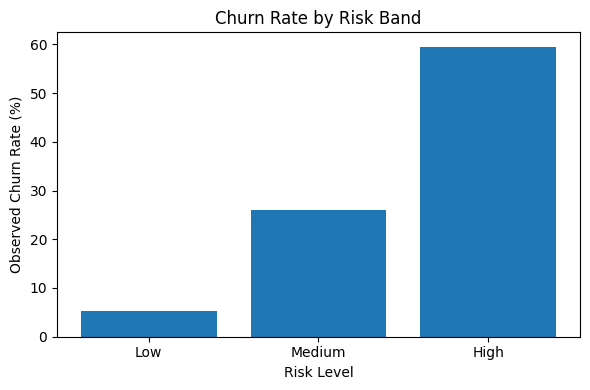

In [52]:
# to group customers by risk level
#mean() helps to calculates average churn
risk = df.groupby('risk_band')['churn'].mean()*100

#arrange risk levels in order
risk = risk.reindex(['Low', 'Medium', 'High'])

#set graph size
plt.figure(figsize=(6, 4))

#to create a bar chart
plt.bar(risk.index, risk.values)

#adding graph title and labels
plt.title('Churn Rate by Risk Band')
plt.xlabel('Risk Level')
plt.ylabel('Observed Churn Rate (%)')

#adjusting spacing
plt.tight_layout()

#saving graph as PNG image
plt.savefig('risk_band_chart.png')

#Display graph
plt.show()

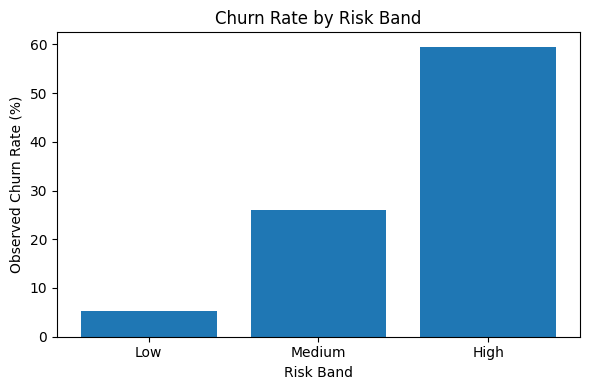

In [53]:
#to calculate churn percentage for each risk group
risk = df.groupby('risk_band')['churn'].mean() * 100

#to arrange risk groups in order
risk = risk.reindex(['Low', 'Medium', 'High'])

#to set graph size
plt.figure(figsize=(6, 4))

#to create bar chart
#risk.index contains Low, Medium, High
#risk.values contains their churn percentages
plt.bar(risk.index, risk.values)

#adding title and labels
plt.xlabel('Risk Band')
plt.ylabel('Observed Churn Rate (%)')
plt.title('Churn Rate by Risk Band')

#adjusting spacing
plt.tight_layout()

#Saving the graph
plt.savefig('risk_band_chart.png')

#Displyig the graph
plt.show()

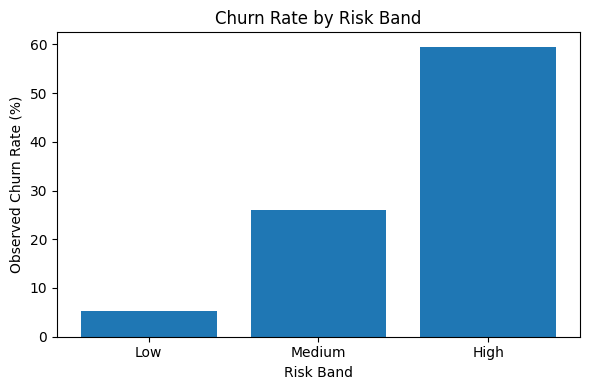

In [54]:
#to calculate churn percentage for each risk group
risk = df.groupby('risk_band')['churn'].mean() * 100

#to arrange risk groups in order
risk = risk.reindex(['Low', 'Medium', 'High'])

#to set graph size
plt.figure(figsize=(6, 4))

#to create bar chart
#risk.index contains risk levels (Low, Medium, High)
#risk.values contains churn percentages
plt.bar(risk.index, risk.values)

#adding graph title and labels
plt.xlabel('Risk Band')
plt.ylabel('Observed Churn Rate (%)')
plt.title('Churn Rate by Risk Band')

#adjusting spacing so labels fit properly
plt.tight_layout()

#saving graph as an image
plt.savefig('risk_band_chart.png')

#displaying graph
plt.show()

In [55]:
#to select customers with High risk
high = df[df['risk_band'] == 'High']

#to count the number of high-risk customers
highcustomers = len(high)

#calculating churn percentage for high-risk customers
highchurn_rate = high['churn'].mean() * 100

#displaying results
print("High Risk Customers:", high_customers)
print("High Risk Churn Rate:", round(high_churn_rate, 2), "%")

NameError: name 'high_customers' is not defined

In [ ]:
#assumption
contactfraction = 0.50
preventionfraction = 0.10

#calculation of number of customers contacted
customerscontacted = high_customers*contact_fraction

#estimation of how many contacted customers might churn
#divide by 100 because high_churn_rate is a percentage
expectedchurn = customers_contacted*(high_churn_rate/100)

# Estimate how many customers could be saved
customerssaved = expectedchurn*preventionfraction

# Display results
print("High-risk customers:", highcustomers)
print("Customers contacted:", round(customerscontacted))
print("Expected churn:", round(expectedchurn, 1))
print("Potential customers saved:", round(customerssaved, 1))

In [ ]:
import os
import shutil

#to create a folder to store project results
os.makedirs('project05_results', exist_ok=True)

#to save cleaned dataset
df.to_csv('project05_results/cleaned_customers.csv', index=False)

#to save churn rate by contract
contract = df.groupby('Contract')['churn'].mean()*100
contract.to_csv('project05_results/churn_by_contract.csv')

#to save churn rate by payment method
payment = df.groupby('PaymentMethod')['churn'].mean()*100
payment.to_csv('project05_results/churn_by_payment.csv')

#to save churn rate by internet service
internet = df.groupby('InternetService')['churn'].mean()*100
internet.to_csv('project05_results/churn_by_internet.csv')

#to save churn rate by risk level
risk = df.groupby('risk_band')['churn'].mean()*100
risk.to_csv('project05_results/risk_bands.csv')

#to save leakage checking table
leakagecheck.to_csv('project05_results/leakage_check.csv', index=False)